# Search a Trade Space

This example demonstrates how to search a trade space of constellation designs for Pareto-efficient designs with the `tatc.tradespace` module: declaring a hierarchical design space, evaluating designs in replicates (in parallel, with a cache of the analysis of each satellite), ranking them with the uncertainty of their replicates, screening them with a cheaper analysis, and searching the space with optimizers (Optuna and pymoo, installed with `pip install tatc[tradespace]`).

The trade is a sampling problem of a pre-Phase A study: how many satellites, in how many orbit planes (each of which needs its own launch), sample the Earth sufficiently often? A point is **sufficiently sampled** if an imager observes it at least four times in a day, and the objective is the share of points that are. A second objective measures sufficiency by its purpose: a point is **accurately sampled** if the mean of its samples estimates the daily mean of a field that varies within hours (such as convective precipitation) with an error of at most half the field's standard deviation. The points are a random sample of the Earth, so the share is a statistical estimate: each replicate of a design draws a different sample of points, which is the uncertainty of the estimate.

## Configure the Scenario

The analysis covers one day, with 100 random points in each of five replicates. A design may have at most 10 satellites.

In [1]:
from datetime import datetime, time as time_of_day, timedelta, timezone
from pathlib import Path
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

START = datetime(2026, 7, 1, tzinfo=timezone.utc)
DURATION = timedelta(days=1)  # the period of the analysis
N_POINTS = 100  # random points sampled in each replicate
N_REPLICATES = 5  # replicates (samples of points) of each design
SAMPLES_PER_DAY = 4  # a point is sufficiently sampled if it is observed at least this often
MAX_SATELLITES = 10
DECORRELATION_TIME = timedelta(hours=3)  # of the field whose daily mean is estimated
MAX_RELATIVE_ERROR = 0.5  # a point is accurately sampled within this share of the field's standard deviation

BLUE, ORANGE, AQUA, YELLOW, GRAY, INK = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a86", "#2b2b29"

## Define the Design Space

A `DesignSpace` declares the design variables, in the order they are decided. Every design has an altitude and an imager's field of regard, and a layout that is one of two alternatives (a `Choice`), each declared with a building block of the `tatc.tradespace` module:

* a **Walker delta** constellation (`walker_space`), with an inclination, a number of planes, a number of satellites in each plane, and the relative spacing of the satellites between planes (whose upper bound depends on the number of planes), or
* one or two **sun-synchronous** planes (`sso_planes_space`, a `Repeat` of planes), each with its own equator crossing time and number of satellites. The planes are unordered: two planes in either order are the same design. A constraint of the building block requires the planes to have different crossing times (otherwise, they would be the same plane).

The points sampled in each replicate are an `Uncertain` parameter (the seed of a random sample, `Uncertain.seed`), drawn for each replicate rather than designed, as are the failures of satellites and the growth of the cost of developing the satellites (both used below). The replicates use common random numbers: every design samples the same points in the same replicate, so that differences between designs are not differences between their samples.

The constraint on the number of satellites returns the number in excess of the limit (a number that is not positive if the design satisfies it), rather than `True` or `False`, so that optimizers can tell how far an infeasible design is from a feasible one.

In [2]:
from tatc.tradespace import (
    Categorical,
    Choice,
    DesignSpace,
    Integer,
    Real,
    Uncertain,
    count_satellites,
    sso_planes_space,
    walker_space,
)

space = DesignSpace(
    altitude=Real(500e3, 800e3, step=100e3),
    field_of_regard=Categorical([30, 60]),
    layout=Choice(
        walker=walker_space(inclination=Real(45, 75, step=15), planes=Integer(1, 4), per_plane=Integer(1, 4)),
        sso=sso_planes_space(crossing=Real(6, 18, step=3), satellites=Integer(1, 2), count=Integer(1, 2)),
    ),
    points_seed=Uncertain.seed(),
    failure_seed=Uncertain.seed(),
    cost_growth=Uncertain(lambda rng: float(rng.triangular(0.9, 1.0, 1.6))),  # of development, for cost risk
    constraints=[lambda d: count_satellites(d.layout) - MAX_SATELLITES],
)
designs = space.enumerate()
print(f"{len(designs)} feasible designs of {len(space.unit_paths())} decisions")

1096 feasible designs of 12 decisions


## Define the Study

A `Study` builds each design into its satellites (`build`, with `build_constellation`, which builds the satellites of either layout with a payload: here, an imager, but also entries of the instrument catalog) and evaluates them (`evaluate`) in each replicate. The evaluation collects the observations of the replicate's points by each satellite, from a `SatelliteCache`: designs share many satellites (the same orbit and imager, if not the same name), whose observations are computed once. The cache is kept on disk, where the parallel worker processes of the study (`n_jobs=-1`, one per processor) share it, and where it persists between sessions. Its namespace identifies the analysis: the points, the start, and the duration.

The evaluation computes both objectives: the share of points with at least four samples, and the share whose sampling error (`tatc.analysis.estimate_sampling_error`, for an exponential correlation in time with a decorrelation time of 3 hours) is at most half the field's standard deviation. A `ResultStore` keeps the records of the evaluations in a file, so that running the notebook again (or resuming it after an interruption) takes them from the file rather than evaluating them again.

`make_study` makes studies of other durations and numbers of replicates, of the phases of deployment, and with failures, as for screening, deployment, and robustness (below). Each evaluation also plans the deployment of the design (`DeploymentSchedule`) and estimates its life-cycle cost (`CostModel`, both used below), and reports the cost of its computation (`satellite_days`, the satellites times the days analyzed), which measures the computation independently of the cache.

In [3]:
from tatc.analysis import collect_observations, estimate_sampling_error
from tatc.generation import generate_points_random
from tatc.schemas import Instrument
from tatc.tradespace import (
    CostModel,
    DeploymentSchedule,
    LaunchCost,
    OperationsCost,
    PhaseCache,
    Requirement,
    RestorationPolicy,
    ResultStore,
    SatelliteCache,
    SatelliteCost,
    Study,
    build_constellation,
    configure,
    count_planes,
    evaluate_missions,
    evaluate_phases,
    summarize_missions,
    summarize_phases,
)

# the deployment of each design: 3 years of development, a production line of 4 satellites a year, launches of up to 3
# satellites at most every half year, and 5 years of operations from the first launch
SCHEDULE = DeploymentSchedule(years=5, development_years=3, production_rate=4, launch_interval=0.5, launch_capacity=3)
# illustrative costs (millions of dollars), not estimates of any mission: satellites with an imager of each field of
# regard, small launchers, and operations, discounted at 3% a year
COST_MODEL = CostModel(
    satellites={
        30: SatelliteCost(development=40, first_unit=12, learning_rate=0.9, mass=60),
        60: SatelliteCost(development=60, first_unit=18, learning_rate=0.9, mass=90),
    },
    launch=LaunchCost(per_launch=8),
    operations=OperationsCost(per_year=3, per_satellite_year=0.5),
    discount_rate=0.03,
)

CACHE_DIRECTORY = Path(tempfile.gettempdir()) / "tatc-search-trade-space"
caches = {}


def get_cache(seed, duration):
    """A cache of the observations by each satellite of the random points of a seed over a duration."""
    if (seed, duration) not in caches:
        points = generate_points_random(N_POINTS, seed=seed)
        caches[seed, duration] = SatelliteCache(
            lambda satellite: collect_observations(points, satellite, START, START + duration),
            directory=CACHE_DIRECTORY,
            namespace=f"{N_POINTS} points, seed {seed}, start {START.isoformat()}, duration {duration}",
        )
    return caches[seed, duration]


def make_study(
    duration=DURATION,
    replicates=N_REPLICATES,
    failures=None,
    policy=None,
    spares=0,
    histories=1,
    phased=False,
    design_space=None,
):
    """A study of the shares (%) of points sampled sufficiently and accurately over a duration by the satellites of
    each design, and (if phased) their means over the phases of the mission as the satellites are deployed and the
    time until half of the points are sampled sufficiently, or (with failures) their means over the phases of
    histories of the mission in which satellites fail and are restored (by a policy, or the policy of each design of
    a design space with one), and their worst 10% of the histories, and the cost at 70% confidence."""
    threshold = SAMPLES_PER_DAY * duration / timedelta(days=1)

    def sample(observations):
        """The shares (%) of points sampled sufficiently and accurately by observations."""
        if len(observations) == 0:  # no satellites
            return {"sufficient": 0.0, "accurate": 0.0}
        samples = observations.groupby("target_hash").size()
        error = estimate_sampling_error(observations, START, START + duration, DECORRELATION_TIME)
        return {
            "sufficient": 100 * (samples >= threshold).sum() / N_POINTS,
            "accurate": 100 * (error.relative_error <= MAX_RELATIVE_ERROR).sum() / N_POINTS,
        }

    # the shares of the sets of satellites that operate in phases, shared by the histories, policies, and designs of a
    # replicate (in a worker's chunk of evaluations)
    phase_cache = PhaseCache(sample)

    def build(d):
        imager = Instrument(name="imager", field_of_regard=d.field_of_regard)
        return d, build_constellation(d.layout, imager, epoch=START, altitude=d.altitude)

    def evaluate(built):
        d, members = built
        # the policy of the design (see policy_space), or the study's
        decided = d.values.get("policy")
        restoration = policy if decided is None else configure(policy or RestorationPolicy(), decided)
        orbit_spares = spares if decided is None else decided.orbit_spares
        deployment = SCHEDULE.plan(d.layout, kind=d.field_of_regard, spares=orbit_spares)
        growth = {"development": d.cost_growth}
        record = {
            "satellites": len(members),
            "planes": count_planes(d.layout),
            **COST_MODEL.estimate(deployment, growth).metrics(),
        }
        cache = get_cache(d.points_seed, duration)
        record.update(sample(cache(members)), satellite_days=len(members) * duration / timedelta(days=1))
        if failures:
            # histories of the mission in the replicate, with failures drawn from its seed, on its points
            missions = evaluate_missions(
                deployment.simulate_many(failures, restoration, d.failure_seed, histories, sampling="stratified"),
                members,
                cache(members),
                phase_cache,
                context=(d.points_seed, duration),
                cost_model=COST_MODEL,
                growth=growth,
            )
            record.update(summarize_missions(missions, quantiles={"accurate mean": 0.1, "cost": 0.7}))
        elif phased:
            capability = evaluate_phases(deployment.phases(members), cache(members), sample)
            record.update(summarize_phases(capability, requirements=[Requirement("sufficient", ">=", 50)]))
        return record

    store = ResultStore(
        CACHE_DIRECTORY / "results.sqlite",
        namespace=f"{N_POINTS} points, start {START.isoformat()}, duration {duration}, "
        + f"accuracy {MAX_RELATIVE_ERROR} at {DECORRELATION_TIME}",
    )
    return Study(design_space or space, build, evaluate, replicates=replicates, n_jobs=-1, store=store)


OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient": "max"}
REFERENCE = {"satellites": MAX_SATELLITES + 1, "planes": 5, "sufficient": 0}  # worse than every design, for hypervolumes

## Evaluate Every Design

The design space is small enough to evaluate every design, which gives the true Pareto front against which the screening and the searches below are compared. `summarize` gives the mean of each objective over the replicates (and its standard deviation and standard error), and `pareto_front` the designs that no other design is as good as in every objective and better than in one.

In [4]:
from tatc.tradespace import hypervolume, pareto_front, summarize

results = make_study().run(designs)
print(f"{len(results)} evaluations: {len(designs)} designs x {N_REPLICATES} replicates")

# the values of each design, and the means of its objectives over the replicates
values = results.drop_duplicates("design").set_index("design").drop(
    columns=["replicate", "points_seed", "failure_seed", "cost_growth", "seconds", "sufficient", "accurate", "feasible"]
)
values = values.drop(columns=[column for column in values.columns if column.startswith("cost")])
summary = summarize(results, list(OBJECTIVES), design_columns=[])
summary["pareto"] = pareto_front(summary, OBJECTIVES)
exact_hypervolume = hypervolume(summary, OBJECTIVES, REFERENCE)


def describe(d):
    """A short description of a design."""
    if d.layout == "walker":
        layout = (
            f"Walker {d['layout.walker.inclination']:.0f} deg: {d['layout.walker.planes']:.0f} x "
            f"{d['layout.walker.per_plane']:.0f} (spacing {d['layout.walker.relative_spacing']:.0f})"
        )
    else:
        planes = [
            f"{d[f'layout.sso.planes[{k}].satellites']:.0f} at {d[f'layout.sso.planes[{k}].crossing']:02.0f}:00"
            for k in range(int(d['layout.sso.planes.count']))
        ]
        layout = "SSO: " + ", ".join(planes)
    return f"{d.altitude / 1e3:.0f} km, {d.field_of_regard} deg FOR, {layout}"


summary["description"] = [describe(values.loc[key]) for key in summary.design]
front = summary[summary.pareto].sort_values(["satellites", "planes"])
front[["description", "satellites", "planes", "sufficient", "sufficient sem"]].round(1)

5480 evaluations: 1096 designs x 5 replicates


,description,satellites,planes,sufficient,sufficient sem
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.2,0.7
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,13.8,1.0
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.6,1.1
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,37.0,1.8
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,66.4,2.2
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,98.0,0.5


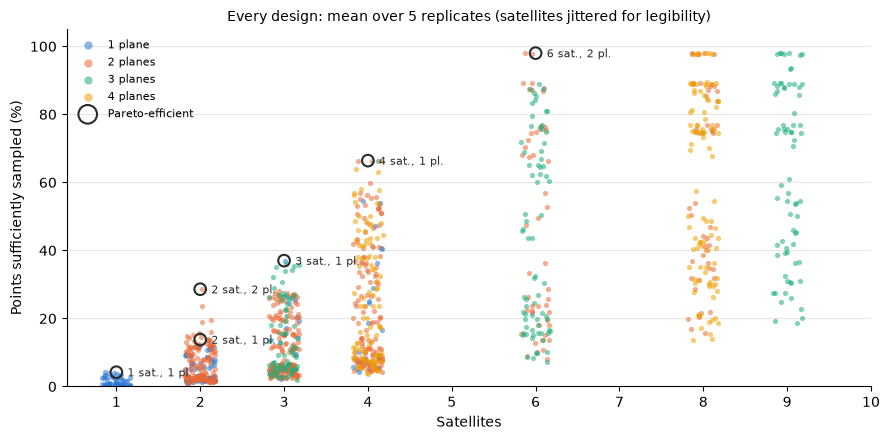

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
PLANE_COLORS = {1: BLUE, 2: ORANGE, 3: AQUA, 4: YELLOW}
jitter = np.random.default_rng(0).uniform(-0.18, 0.18, len(summary))
for planes, color in PLANE_COLORS.items():
    selected = summary.planes == planes
    ax.scatter(
        summary.satellites[selected] + jitter[selected],
        summary.sufficient[selected],
        s=14,
        color=color,
        alpha=0.55,
        lw=0,
        label=f"{planes} plane{'s' if planes > 1 else ''}",
    )
# the efficient designs, ringed and labeled
ax.scatter(front.satellites, front.sufficient, s=70, facecolor="none", edgecolor=INK, lw=1.5, label="Pareto-efficient")
for _, row in front.iterrows():
    ax.annotate(
        f"{row.satellites:.0f} sat., {row.planes:.0f} pl.",
        (row.satellites, row.sufficient),
        xytext=(8, -3),
        textcoords="offset points",
        fontsize=8,
        color=INK,
    )
ax.set(
    xlabel="Satellites",
    ylabel="Points sufficiently sampled (%)",
    xticks=range(1, MAX_SATELLITES + 1),
    ylim=(0, 105),
)
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", fontsize=8, frameon=False, markerscale=1.6)
ax.set_title("Every design: mean over 5 replicates (satellites jittered for legibility)", fontsize=10)
fig.tight_layout()
plt.show()

Of the 1,096 feasible designs, six are Pareto-efficient (ringed in the figure). All of them fly at the highest altitude (800 km) with the wider field of regard (60 degrees), which observe the most points per satellite, so the trade is in the number of satellites and planes. One satellite samples only 4% of the points sufficiently (at least four times a day), and the share rises steeply with the number of satellites: two satellites in two planes (29%) sample twice as many points as two in one plane (14%), and six satellites in two inclined planes sample 98%. No design with more than six satellites is efficient, because six already sample nearly every point. Designs with the same number of satellites differ widely: their layout (inclination, planes, and phasing) matters as much as their number.

## Measure the Sampling Error

Four samples a day count the same whether they come hours apart or minutes apart, but they do not estimate a daily mean equally well: samples closer together than the field's decorrelation time repeat each other. The share of points accurately sampled measures what the samples are for. The table gives the efficient designs by this objective (with the numbers of satellites and planes, as before), and the figure compares the two objectives for every design.

In [6]:
ACCURACY = {"satellites": "min", "planes": "min", "accurate": "max"}
accuracy = summarize(results, ["satellites", "planes", "sufficient", "accurate"], design_columns=[])
accuracy["description"] = [describe(values.loc[key]) for key in accuracy.design]
accuracy["pareto"] = pareto_front(accuracy, ACCURACY)
accuracy[accuracy.pareto].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient", "accurate", "accurate sem"]
].round(1)

,description,satellites,planes,sufficient,accurate,accurate sem
1046,"800 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,3.4,4.8,1.0
1049,"800 km, 60 deg FOR, SSO: 2 at 09:00",2.0,1.0,11.6,11.4,0.9
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.6,33.8,1.7
1019,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",3.0,1.0,24.6,19.2,1.1
1088,"800 km, 60 deg FOR, SSO: 2 at 12:00, 1 at 15:00",3.0,2.0,26.4,58.0,1.5
972,"800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,36.0,58.6,1.3
1020,"800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...",4.0,1.0,47.2,27.2,1.2
1079,"800 km, 60 deg FOR, SSO: 2 at 12:00, 2 at 09:00",4.0,2.0,52.2,82.8,1.3
758,"700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...",6.0,3.0,87.4,97.0,0.5
1035,"800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,98.0,98.0,0.5


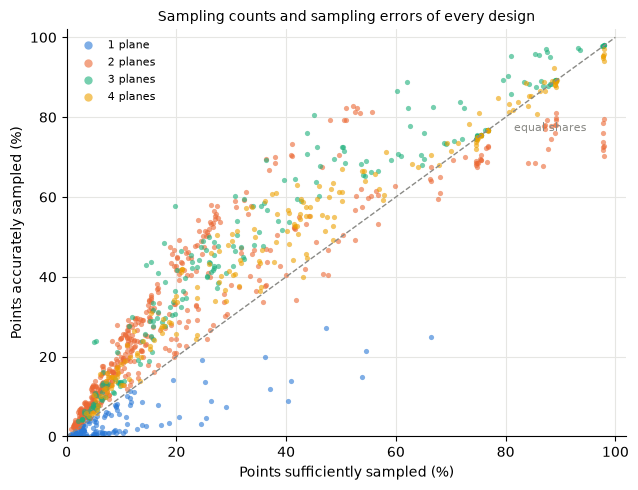

In [7]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for planes, color in PLANE_COLORS.items():
    selected = accuracy.planes == planes
    ax.scatter(
        accuracy.sufficient[selected], accuracy.accurate[selected], s=14, color=color, alpha=0.6, lw=0,
        label=f"{planes} plane{'s' if planes > 1 else ''}",
    )
ax.plot([0, 100], [0, 100], color=GRAY, lw=1, ls="--")
ax.annotate("equal shares", (80, 80), xytext=(6, -10), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(xlabel="Points sufficiently sampled (%)", ylabel="Points accurately sampled (%)", xlim=(0, 102), ylim=(0, 102))
ax.grid(color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="upper left", fontsize=8, frameon=False, markerscale=1.6)
ax.set_title("Sampling counts and sampling errors of every design", fontsize=10)
fig.tight_layout()
plt.show()

The revisits of two designs of four satellites with similar shares of points sufficiently sampled show why they differ in accuracy: the times between their samples (`tatc.analysis.compute_revisit_statistics`), including the longest gap of the day, and the times of day they sample (`tatc.analysis.compute_local_time_coverage`, in eight 3-hour intervals of local time).

In [8]:
from tatc.analysis import compute_local_time_coverage, compute_revisit_statistics

four = accuracy[(accuracy.satellites == 4)].sort_values("sufficient", ascending=False)
# the most sufficiently sampling design of four satellites, and the most accurately sampling one of another layout
first = four.iloc[0]
second = four[four.design != first.design].sort_values("accurate", ascending=False).iloc[0]
by_key = {d.key: d for d in designs}
rows = []
for row in (first, second):
    d = by_key[row.design].realize(0)
    _, members = make_study().build(d)
    observations = get_cache(d.points_seed, DURATION)(members)
    points = generate_points_random(N_POINTS, seed=d.points_seed)
    revisits = compute_revisit_statistics(observations, START, START + DURATION, targets=points)
    local = compute_local_time_coverage(observations, targets=points)
    observed = revisits[revisits.samples > 0]
    rows.append(
        {
            "design": row.description,
            "sufficient (%)": row.sufficient,
            "accurate (%)": row.accurate,
            "median revisit (h)": observed["revisit p50"].dt.total_seconds().median() / 3600,
            "median longest gap (h)": revisits.max_gap.dt.total_seconds().median() / 3600,
            "median 3-h intervals sampled": local.local_bins_sampled.median(),
        }
    )
pd.DataFrame(rows).set_index("design").round(1)

,sufficient (%),accurate (%),median revisit (h),median longest gap (h),median 3-h intervals sampled
design,,,,,
"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spacing 0)",66.4,25.0,0.4,14.5,2.0
"800 km, 60 deg FOR, SSO: 2 at 12:00, 2 at 09:00",52.2,82.8,5.6,10.4,3.0


Counting samples and measuring their sampling error rank designs differently. Satellites in one plane (blue in the figure) sample many points four times a day, but in bursts: consecutive passes of satellites that follow each other in a plane, minutes apart, repeat each other for a field that decorrelates in hours. Four satellites in one Walker plane sample 66% of the points at least four times a day, but only 25% accurately: half of their revisits are 0.4 hours apart, and they leave a gap of 14.5 hours. Four satellites in two sun-synchronous planes sample fewer points four times (52%) but 83% accurately: their samples are 5.6 hours apart, in three of the eight 3-hour intervals of the day. Designs in a single plane remain efficient only as those that need the fewest launches, and sample at most 27% of the points accurately; six satellites in three planes sample 97% of the points accurately, as many as nine.

## Find What Drives the Objectives

`sensitivity` gives the share of the variance of each objective (over the designs, by their means over the replicates) that each design variable explains, among the designs in which the variable is active: the variables of the Walker layout apply only to Walker designs, and those of the sun-synchronous layout only to theirs. The shares are adjusted for the variance that the levels of a variable would explain by chance, which matters for samples of designs and for variables of many levels.

In [9]:
from tatc.tradespace import sensitivity

frame = accuracy.join(values.drop(columns=["satellites", "planes", "satellite_days"]), on="design")
variables = [
    "altitude",
    "field_of_regard",
    "layout",
    "layout.walker.inclination",
    "layout.walker.planes",
    "layout.walker.per_plane",
    "layout.walker.relative_spacing",
    "layout.sso.planes.count",
]
sensitivity(frame, variables, ["sufficient", "accurate"]).round(2)

,sufficient,accurate,active
variable,,,
field_of_regard,0.25,0.25,1.00
layout.walker.per_plane,0.22,0.18,0.64
layout,0.18,0.12,1.00
layout.walker.planes,0.12,0.29,0.64
layout.sso.planes.count,0.11,0.19,0.36
altitude,0.03,0.03,1.00
layout.walker.relative_spacing,0.03,0.06,0.64
layout.walker.inclination,0.00,0.00,0.64


The field of regard explains the most of both objectives (25% of their variance), as it sets the swath of every satellite. The layout matters next, but differently for the two objectives: the number of satellites in each Walker plane explains more of the share of points sufficiently sampled (22%) than of those accurately sampled (18%), and the number of Walker planes the reverse (12% and 29%), as more planes spread the samples in time. The altitude explains little of either objective (3%), although a higher orbit widens the swath: its effect is small next to those of the field of regard and the layout. The inclination explains nothing on average over the Walker designs.

## Rank Designs with the Uncertainty of Replicates

The means of five replicates are uncertain, and so is the front of the means: a design just behind another in the means may be ahead of it in other samples of points. `pareto_probability` estimates the probability that each design is efficient by a bootstrap: it resamples the replicates (the same replicates for every design, which keeps the correlation between designs of common random numbers) and counts how often each design is on the front of the resampled means.

In [10]:
from tatc.tradespace import pareto_probability

probability = pareto_probability(results, OBJECTIVES, n_resamples=1000)
probability["description"] = [describe(values.loc[key]) for key in probability.design]
candidates = probability[probability.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])
candidates[["description", "satellites", "planes", "sufficient", "pareto", "pareto_probability"]].round(2)

,description,satellites,planes,sufficient,pareto,pareto_probability
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,4.0,False,0.25
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,4.0,False,0.42
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.2,True,0.74
1051,"800 km, 60 deg FOR, SSO: 2 at 12:00",2.0,1.0,12.2,False,0.22
960,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,13.8,True,0.78
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.6,True,1.00
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,37.0,True,1.00
1001,"800 km, 60 deg FOR, Walker 60 deg: 3 x 1 (spac...",3.0,3.0,35.4,False,0.29
698,"700 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,35.8,False,0.28
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,66.4,True,1.00


Four of the six efficient designs are efficient in every resample: two satellites in two planes, three or four satellites in one plane, and six in two planes. The others are not settled by five replicates. One satellite in a sun-synchronous orbit crossing the equator at 09:00 (efficient in 74% of the resamples) samples about as many points as one crossing at 15:00 or 18:00 (25% and 42%), and six satellites in two planes with another relative spacing (32%) sample about as many as the efficient design. Designs that are efficient with a probability between 0 and 1 are equally good candidates, given the uncertainty of the estimates: more replicates (samples of points) would separate them, or a tolerance of the share (see `pareto_front`) would treat them as ties.

## Refine Uncertain Designs

Five replicates settle the efficiency of most designs, but not of all. More replicates of every design would settle them, at the cost of evaluating every design again for each. `refine` instead adds replicates only to the designs whose efficiency is uncertain (efficient in more than 5% and fewer than 95% of the resamples), five at a time, and estimates their probabilities again, until none is uncertain (or a design has 40 replicates). The added replicates are the next ones after each design's own, which keeps common random numbers between the designs refined together.

Some designs differ by less than any number of replicates could separate, such as those that sample nearly every point: a difference of a tenth of a percentage point does not matter to the trade. A tolerance of 1 percentage point of the share treats designs within it of the front as efficient (see `pareto_front`), so that refinement does not spend replicates on differences that do not matter.

In [11]:
from tatc.tradespace import refine

TOLERANCE = {"sufficient": 1.0}  # percentage points of the share that do not matter
refinement = refine(
    make_study(), designs, results, OBJECTIVES, step=5, max_replicates=40, n_resamples=1000, tolerance=TOLERANCE
)
added = len(refinement.results) - len(results)
print(f"{added} evaluations added, {added / (len(designs) * 35):.1%} of those of 40 replicates of every design")
refinement.history

655 evaluations added, 1.7% of those of 40 replicates of every design


,round,uncertain,refined,evaluations
0,0,20,20,100
1,1,21,21,105
2,2,18,18,90
3,3,17,17,85
4,4,15,15,75
5,5,14,14,70
6,6,15,15,75
7,7,13,6,30
8,8,12,3,15
9,9,12,2,10


In [12]:
refined = refinement.probability
refined["description"] = [describe(values.loc[key]) for key in refined.design]
refined[refined.pareto_probability >= 0.1].sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient", "replicates", "pareto", "pareto_probability"]
].round(2)

,description,satellites,planes,sufficient,replicates,pareto,pareto_probability
772,"700 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,2.68,40,False,0.16
774,"700 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,2.70,40,False,0.19
778,"700 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,2.70,40,False,0.18
780,"700 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,2.72,40,False,0.19
1017,"800 km, 60 deg FOR, Walker 75 deg: 1 x 1 (spac...",1.0,1.0,3.12,40,False,0.45
1046,"800 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,3.40,40,True,0.63
1050,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.40,40,True,0.64
1054,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.42,40,True,0.65
1052,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,4.00,5,True,0.99
1048,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.20,5,True,0.99


Refinement adds 655 evaluations, 1.7% of those that 40 replicates of every design would take, to the few designs whose efficiency is uncertain. With the tolerance, the designs that sample nearly every point (six to nine satellites, about 98%) are all efficient candidates, with probabilities of 0.92 or more, rather than uncertain: they differ by less than matters. The designs that stay uncertain after ten rounds lie about one tolerance below the front, such as single satellites that sample about 3.4% of the points against the best single satellite's 4.2%: whether they are within the tolerance of the front is a question that more replicates settle only slowly, and one that does not change the trade. An absolute tolerance suits a share near saturation better than one near zero; a tolerance proportional to the objective would treat both alike.

## Confirm the Front

The efficient designs were selected for their means over their replicates, so they are selected in part for the luck of those replicates: among a thousand designs, those that look best are likely to have drawn favorable samples of points (the winner's curse). `confirm` evaluates the selected designs with new replicates, which played no part in their selection (the same for every design, which keeps common random numbers), and finds the front among them by these replicates. The difference between the means of the replicates that selected the designs and those of the new ones measures the optimism of the selection.

In [13]:
from tatc.tradespace import confirm

selected = [by_key[key] for key in refined.design[refined.pareto]]
confirmation = confirm(make_study(), selected, refinement.results, OBJECTIVES, replicates=20, tolerance=TOLERANCE)
confirmed = confirmation.summary
confirmed["description"] = [describe(values.loc[key]) for key in confirmed.design]
print(f"optimism of the selection: {confirmation.optimism(OBJECTIVES)['sufficient']:.2f} percentage points")
confirmed.sort_values(["satellites", "planes", "sufficient"])[
    ["description", "satellites", "planes", "sufficient selected", "sufficient", "replicates", "pareto"]
].round(2)

optimism of the selection: -0.35 percentage points


,description,satellites,planes,sufficient selected,sufficient,replicates,pareto
33,"800 km, 60 deg FOR, SSO: 1 at 18:00",1.0,1.0,3.42,2.65,20,True
29,"800 km, 60 deg FOR, SSO: 1 at 06:00",1.0,1.0,3.40,2.75,20,True
30,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,4.20,2.80,20,True
31,"800 km, 60 deg FOR, SSO: 1 at 12:00",1.0,1.0,3.40,2.90,20,True
32,"800 km, 60 deg FOR, SSO: 1 at 15:00",1.0,1.0,4.00,2.90,20,True
11,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,14.13,14.70,20,True
14,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,28.60,27.55,20,True
12,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,37.00,37.15,20,True
17,"800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...",3.0,3.0,37.40,37.40,20,True
13,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,66.40,66.85,20,True


The selection is optimistic where it chose among many nearly equal designs. The single satellites, the best of dozens of single-satellite designs that sample 3 to 4% of the points, sample 2.7 to 2.9% with the new replicates, 0.5 to 1.4 percentage points fewer, and the one that looked best (crossing the equator at 09:00, with 4.2%) is no better than the others. The designs of two to nine satellites confirm their shares within about a percentage point. Most sample slightly more points with the new replicates (by 0.2 to 0.9 points), as the new samples of points happen to be sampled more easily by every design: common random numbers share this difference between samples among the designs, and it is not an effect of the selection. The mean optimism over the designs (-0.35 points) mixes the two, so compare the designs one by one. Every confirmed design remains efficient within the tolerance: the shape of the front is confirmed, but its single-satellite end is less good than it looked.

## Require Reliable Sampling

A mean share of points sufficiently sampled does not say how reliably a design achieves it: the share differs between samples of points. Statistics over the replicates other than the mean state how a design is judged, and requirements on them are output constraints. Here, the objective is the share that a design exceeds in 80% of the samples (its 0.2 quantile, `Quantile`), and a design is required to sample at least half of the points sufficiently in at least 80% of the samples (the probability of meeting a threshold, `Probability`, with a `Requirement`). `aggregate` gives the statistics and the violations of the requirements, and `pareto_probability` the probability that each design is efficient among those that meet them.

In [14]:
from tatc.tradespace import Probability, Quantile, Requirement, aggregate

STATISTICS = {
    "sufficient p20": Quantile("sufficient", 0.2),
    "reliability": Probability("sufficient", ">=", 50),
}
RELIABLE_OBJECTIVES = {"satellites": "min", "planes": "min", "sufficient p20": "max"}
REQUIREMENTS = [Requirement("reliability", ">=", 0.8)]

reliable = pareto_probability(
    refinement.results, RELIABLE_OBJECTIVES, n_resamples=1000, statistics=STATISTICS, requirements=REQUIREMENTS
)
reliable["description"] = [describe(values.loc[key]) for key in reliable.design]
print(f"{reliable.meets_requirements.sum()} of {len(reliable)} designs meet the requirement")
reliable[reliable.pareto_probability >= 0.1].sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "sufficient p20", "reliability", "replicates", "pareto_probability", "requirements_probability"]
].round(2)

194 of 1096 designs meet the requirement


,description,satellites,planes,sufficient p20,reliability,replicates,pareto_probability,requirements_probability
962,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,61.8,1.0,5,1.00,1.0
965,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,61.8,1.0,5,0.24,1.0
966,"800 km, 60 deg FOR, Walker 45 deg: 2 x 2 (spac...",4.0,2.0,62.4,1.0,5,0.38,1.0
980,"800 km, 60 deg FOR, Walker 45 deg: 4 x 1 (spac...",4.0,4.0,63.8,1.0,40,0.45,1.0
1025,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.4,1.0,5,0.47,1.0
1026,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,97.6,1.0,5,1.00,1.0
487,"600 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,35,0.12,1.0
762,"700 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,25,0.12,1.0
763,"700 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...",9.0,3.0,96.8,1.0,25,0.11,1.0


194 of the 1,096 designs meet the requirement of sampling half of the points sufficiently in at least 80% of the samples, and none of them has fewer than four satellites: the best three satellites sample 37% of the points on average. Among those that meet it, four satellites in one plane (inclined 45 degrees) are efficient for sure, sampling at least 62% of the points in 80% of the samples, and so are six satellites in two planes inclined 75 degrees (at least 97%). Four satellites in two or four planes are nearly as good, with probabilities of 0.24 to 0.45, which are the alternatives to weigh with other criteria, such as the cost of launching more planes.

## Plan for Failures

A design that needs every satellite to work is fragile, and what failures cost depends on how the mission responds to them. A `FailureModel` gives the life of the satellites from their launch, here a bathtub curve of infant mortality, random failures, and wear-out (`Bathtub` of `Weibull` and `Exponential` lives, illustrative), and the probability that a launch fails. Each replicate simulates the mission of a design with failures drawn from its seed (`Deployment.simulate`, with common random numbers: the satellite at the same position of the same plane fails at the same age in every design), and a `RestorationPolicy` responds to them:

* **degrade**: fly the satellites that remain;
* **produce**: restore each failed satellite by producing a new one (after half a year of procurement, on the production line) and launching it;
* **spare in orbit**: a spare in each plane, launched with it, takes a failed satellite's place within months (others are produced), and is produced again;
* **spare on ground**: a spare, produced after the first satellites and stored, is launched at the next slot (others are produced), and is produced again.

The policy is a decision of each design: a fragment of the design space (`policy_space`) decides whether to restore failed satellites, and the spares in orbit (in each plane) and on the ground (here, none or one of each, and none without restoration, which would never use them), and configures the policy of each design (`configure`, from a base policy of half a year of procurement and spares that are produced again). The efficient designs by accuracy, each with each of the five policies, form a design space of both, in which each history gives both the cost of what is produced and launched (the restorations and spares, and the launches that fail) and the phases in which its satellites operate, evaluated as in the previous section: the share of points accurately sampled on average over the mission, and in the worst 10% of the histories, and the cost at 70% confidence.

The failures are cheap to simulate, but each phase's share is expensive to evaluate, and most phases repeat the same sets of operating satellites. Each replicate (a sample of points, the expensive part) therefore simulates 20 histories of the failures of its mission (`Deployment.simulate_many`, stratified: a Latin hypercube over the histories in which each satellite's life and each launch draws from its own stratum of its distribution, which estimates means several times more precisely than independent histories), evaluates them together (`evaluate_missions`) with a cache that evaluates each set of satellites once (`PhaseCache`, shared by the histories, policies, and designs of a replicate), and summarizes them (`summarize_missions`): their mean share, and their worst 10% (the risk of the mission), and their cost at 70% confidence. Five replicates of 20 histories measure the risk of each mission with 100 histories, at a fraction of the cost of 100 replicates.

In [15]:
import time

from tatc.tradespace import Bathtub, Exponential, FailureModel, Integer, Weibull, policy_space

# illustrative lives: about 9% fail in their first year, 3% a year at random, and wear-out after about 8 years
FAILURES = FailureModel(
    life=Bathtub(infant=Weibull(shape=0.5, scale=100), random=Exponential(0.03), wear_out=Weibull(shape=4, scale=9)),
    launch=0.05,
)
print(f"{1 - FAILURES.life.survival(5):.0%} of the satellites fail in 5 years")
BASE_POLICY = RestorationPolicy(procurement_years=0.5, replenish=True)
POLICY = policy_space(orbit_spares=Integer(0, 1), ground_spares=Integer(0, 1), replenish=True)

# the design space with a policy, and the efficient designs by accuracy with each policy
policy_trade = DesignSpace(**space.children, policy=POLICY, constraints=space.constraints)
with_policies, base_of = [], {}
for key in accuracy.design[accuracy.pareto]:
    for policy in POLICY.enumerate():
        design = policy_trade.design({**by_key[key].decisions, "policy": policy.decisions})
        with_policies.append(design)
        base_of[design.key] = key


def describe_policy(row):
    """A short description of a policy."""
    if not row["policy.restore"]:
        return "degrade"
    orbit, ground = row["policy.orbit_spares"] > 0, row["policy.ground_spares"] > 0
    return {
        (False, False): "produce",
        (True, False): "spare in orbit",
        (False, True): "spare on ground",
        (True, True): "spares in orbit and on ground",
    }[orbit, ground]


study = make_study(replicates=5, failures=FAILURES, policy=BASE_POLICY, histories=20, design_space=policy_trade)
began = time.perf_counter()
trades = study.run(with_policies)
print(f"{len(with_policies)} designs x 5 replicates x 20 histories in {time.perf_counter() - began:.0f} s")
# the means over the replicates of the histories' mean share, worst 10%, and cost at 70% confidence
ROBUST = {"accurate": "accurate mean", "accurate p10": "accurate mean p10", "cost p70": "cost p70"}
traded = aggregate(trades, ROBUST).set_index("design")[list(ROBUST)]
first = trades.drop_duplicates("design").set_index("design")
traded["policy"] = [describe_policy(first.loc[key]) for key in traded.index]
traded["base"] = [base_of[key] for key in traded.index]

# the shares of the full constellations, without deployment or failures, for comparison
nominal = make_study(replicates=20).run([by_key[key] for key in accuracy.design[accuracy.pareto]])
full = aggregate(nominal, ["accurate"]).set_index("design")["accurate"]
ORDER = ["degrade", "produce", "spare in orbit", "spare on ground", "spares in orbit and on ground"]
table = traded.pivot(index="base", columns="policy", values=["accurate", "accurate p10", "cost p70"])
table = table[[(metric, policy) for metric in ("accurate", "accurate p10", "cost p70") for policy in ORDER]]
table.insert(0, ("full constellation", ""), full.reindex(table.index))
table.insert(0, ("description", ""), [describe(values.loc[key]) for key in table.index])
table.sort_values(("full constellation", "")).round(1)

37% of the satellites fail in 5 years


60 designs x 5 replicates x 20 histories in 3 s


description  \
policy                                                            
base                                                              
de5bf5d3c148                800 km, 60 deg FOR, SSO: 1 at 06:00   
7274d007018f                800 km, 60 deg FOR, SSO: 2 at 09:00   
b85daf65c3a4  800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...   
104e33a3c842  800 km, 60 deg FOR, Walker 75 deg: 1 x 4 (spac...   
33b006848799  800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...   
ceabaa8327b8    800 km, 60 deg FOR, SSO: 2 at 12:00, 1 at 15:00   
92ff9cd17e00  800 km, 60 deg FOR, Walker 45 deg: 3 x 1 (spac...   
25d7b27dab28    800 km, 60 deg FOR, SSO: 2 at 12:00, 2 at 09:00   
716cb479efda  700 km, 60 deg FOR, Walker 75 deg: 3 x 2 (spac...   
5529c21520be  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   
679ca275c8fc  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   
de505bc89299  800 km, 60 deg FOR, Walker 75 deg: 3 x 3 (spac...   

             full constellation accurate                         \
policy                           degrade produce spare in orbit   
base                                                              
de5bf5d3c148                3.9      3.5     4.4            4.6   
7274d007018f                9.6      8.2    10.3           10.7   
b85daf65c3a4               16.7     12.2    16.7           16.5   
104e33a3c842               28.6     15.6    21.5           23.4   
33b006848799               31.7     16.3    25.7           27.8   
ceabaa8327b8               54.8     31.9    45.9           48.9   
92ff9cd17e00               57.8     32.6    44.2           46.9   
25d7b27dab28               82.2     49.0    66.4           66.8   
716cb479efda               97.2     63.8    77.8           73.9   
5529c21520be               98.0     80.1    83.3           77.1   
679ca275c8fc               98.0     80.3    83.4           77.1   
de505bc89299               98.0     80.2    83.3           77.0   

                                                           accurate p10  \
policy       spare on ground spares in orbit and on ground      degrade   
base                                                                      
de5bf5d3c148             4.6                           4.6          0.5   
7274d007018f            10.9                          10.8          3.7   
b85daf65c3a4            18.1                          16.7          5.0   
104e33a3c842            23.3                          23.9          6.2   
33b006848799            28.6                          28.1          0.6   
ceabaa8327b8            49.9                          49.4          8.7   
92ff9cd17e00            46.9                          47.1         11.2   
25d7b27dab28            70.4                          67.3         12.8   
716cb479efda            79.5                          74.0         39.3   
5529c21520be            83.4                          77.1         66.1   
679ca275c8fc            83.4                          77.1         67.6   
de505bc89299            83.3                          77.0         66.9   

                                                     \
policy       produce spare in orbit spare on ground   
base                                                  
de5bf5d3c148     4.0            4.3             4.2   
7274d007018f     8.6            9.5             9.7   
b85daf65c3a4    14.0           14.3            16.1   
104e33a3c842    17.8           19.7            20.4   
33b006848799    19.1           24.7            25.2   
ceabaa8327b8    37.7           43.3            44.2   
92ff9cd17e00    37.7           42.7            41.8   
25d7b27dab28    54.2           59.0            60.1   
716cb479efda    70.1           67.9            71.4   
5529c21520be    78.5           71.7            78.5   
679ca275c8fc    78.6           72.0            78.4   
de505bc89299    78.5           71.8            78.3   

                                           cost p70                         \
policy    

The 6,000 histories (100 of each of the 60 designs and policies) take a few seconds here, against about as long for 1,200 histories of one per replicate without the cache. The shares accurately sampled over the mission fall short of those of the full constellation under every policy, by the phases of deployment and the failures of launches as well as of satellites (37% of which fail within five years). The response to failures matters most for the designs of several satellites in several planes, and in their worst histories:

* **Degrading** is cheapest, but loses 12 to 17 points of the mean against producing replacements for the designs of three to six satellites in two or three planes, and more in their worst 10% of histories (39% against 70% for six satellites in three Walker planes; 1% against 19% for two satellites in two planes, which can lose both). Nine satellites in three planes lose only 3 points: a failure leaves eight.
* **Producing replacements** restores most of it, at 17 to 34% more cost at 70% confidence than degrading.
* **Spares** cost 28 to 56% more than degrading, and pay off in the worst histories of the small designs of several planes: two satellites in two planes keep about 25% in their worst histories with a spare, against 19% by producing replacements. A spare on the ground costs less than a spare in each plane for the designs of several planes, and restores about as well.
* **A spare in orbit can hurt**: for six or nine satellites in three planes, the spares delay the deployment (each plane's spare takes longer to produce, and a fourth satellite in a plane takes a second launch of up to three), so that they sample less on average (74% against 78% for six satellites, 77% against 83% for nine) at a higher cost. Spares in orbit and on the ground together cost the most, and sample about as much as a spare on the ground alone, or less.

In [16]:
# the efficient designs and policies, by their cost and their accuracy in the worst 10% of the replicates
efficient = traded[pareto_front(traded, {"cost p70": "min", "accurate p10": "max"})]
efficient.assign(description=[describe(values.loc[key]) for key in efficient.base]).sort_values("cost p70")[
    ["description", "policy", "accurate", "accurate p10", "cost p70"]
].round(1)

,description,policy,accurate,accurate p10,cost p70
design,,,,,
56ce6ae8edc1,"800 km, 60 deg FOR, SSO: 1 at 06:00",degrade,3.5,0.5,110.2
21919a7c8e69,"800 km, 60 deg FOR, SSO: 2 at 09:00",degrade,8.2,3.7,128.9
098de5b3e423,"800 km, 60 deg FOR, SSO: 1 at 06:00",produce,4.4,4.0,130.6
638697713902,"800 km, 60 deg FOR, Walker 75 deg: 1 x 3 (spac...",degrade,12.2,5.0,146.2
dcfeee8eff41,"800 km, 60 deg FOR, SSO: 2 at 09:00",produce,10.3,8.6,153.4
dbca2b91551b,"800 km, 60 deg FOR, SSO: 2 at 12:00, 1 at 15:00",degrade,31.9,8.7,153.9
ad99c42082ab,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",produce,25.7,19.1,159.4
cc2e14e787ff,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",spare on ground,28.6,25.2,175.2
2f843d5c75f6,"800 km, 60 deg FOR, SSO: 2 at 12:00, 1 at 15:00",produce,45.9,37.7,198.1


The front of cost at 70% confidence against the share accurately sampled in the worst 10% of the histories chooses designs and policies together. Along it, degrading is the cheapest policy of a design and restoring buys robustness: three satellites in two sun-synchronous planes keep 9% of the points accurately sampled in their worst histories if they degrade (154 million), 38% if they produce replacements (198 million), and 44% with a spare on the ground (212 million); six satellites in three Walker planes keep 39%, 70%, and 71% for 210, 279, and 294 million. Nine satellites in three planes degrade gracefully (68% in their worst histories for 254 million), and producing replacements raises them to 79% for 340 million. A spare on the ground is efficient for designs of two to six satellites, but a spare in orbit is not efficient for any design here, as it delays the deployment. The policy that a design deserves depends on the design, which is why the policy is a decision of the design rather than of the study.

## Trade Cost Against Sufficiency

The numbers of satellites and planes are proxies of cost. A `CostModel` estimates the life-cycle cost of each design from the costs of its satellites (the development of each type, and the production of its units on a learning curve), launches (here, a small launcher for every three satellites of a plane), and operations, given by the study (TAT-C does not include cost-estimating relationships). The costs here are illustrative, in millions of dollars. The evaluation adds the cost and its elements to each record, for the satellites of each design's imager (`kind`): a wider field of regard costs more to develop and build. The deployment of each design (`DeploymentSchedule.plan`) dates the costs, from rates, so that each design's schedule follows from its satellites and planes: development over three years, then the production of the satellites on one line at four a year, plane by plane, each plane launched when its satellites are ready (in launches of up to three satellites, at most one every half year), and operations from each launch to the end of the mission (five years after the first launch). The dated costs give the present value of the cost (`cost present`, discounted at 3% a year) and the cost of the most expensive year (`cost peak annual`), for annual budgets.

The growth of the cost of development is uncertain (an `Uncertain` parameter, from 0.9 to 1.6 times the estimate, most likely 1), drawn for each replicate, so that statistics over the replicates give the cost at a confidence level: here, the 0.7 quantile (`cost p70`), as budgets are often set. A requirement keeps the designs whose cost at 70% confidence is within a budget, and the front trades this cost against the share of points sufficiently sampled. (Cost depends only on the design, so a constraint of the design space could exclude designs over a budget before they are evaluated, with the cost without growth.)

In [17]:
BUDGET = 150  # millions of dollars, at 70% confidence
COST_STATISTICS = {"cost p70": Quantile("cost", 0.7)}
COST_OBJECTIVES = {"cost p70": "min", "sufficient": "max"}
ELEMENTS = ["cost development", "cost production", "cost launch", "cost operations"]

costed = pareto_probability(
    refinement.results,
    COST_OBJECTIVES,
    n_resamples=1000,
    statistics=COST_STATISTICS,
    requirements=[Requirement("cost p70", "<=", BUDGET)],
    tolerance=TOLERANCE,
)
DATED = ["cost present", "cost peak annual"]
elements = aggregate(refinement.results, [*ELEMENTS, *DATED]).set_index("design")[[*ELEMENTS, *DATED]]
costed = costed.join(values[["satellites", "planes"]], on="design").join(elements, on="design")
costed["description"] = [describe(values.loc[key]) for key in costed.design]
# the years from the start of development to the launch of every plane, from each design's schedule
costed["deployed"] = [
    SCHEDULE.plan(by_key[key].layout, kind=by_key[key].field_of_regard).deployed for key in costed.design
]
efficient = costed[costed.pareto_probability >= 0.5]
print(
    f"{costed.meets_requirements.sum()} of {len(costed)} designs cost at most {BUDGET} at 70% confidence, "
    + f"of which {len(efficient)} are efficient in at least half of the resamples"
)
# the most sufficient of these at each cost
efficient.sort_values(["cost p70", "sufficient"], ascending=[True, False]).drop_duplicates("cost p70")[
    ["description", "satellites", "planes", "deployed", "cost p70", *ELEMENTS, *DATED, "sufficient", "pareto_probability"]
].round(1)

520 of 1096 designs cost at most 150 at 70% confidence, of which 34 are efficient in at least half of the resamples


,description,satellites,planes,deployed,cost p70,cost development,cost production,cost launch,cost operations,cost present,cost peak annual,sufficient,pareto_probability
913,"800 km, 30 deg FOR, SSO: 1 at 12:00",1,1,3.2,83.6,44.4,12.0,8.0,17.5,75.5,23.5,1.0,1.0
912,"800 km, 30 deg FOR, SSO: 2 at 09:00",2,1,3.5,96.9,44.4,22.8,8.0,20.0,87.2,30.8,3.2,0.9
826,"800 km, 30 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,104.7,44.4,22.8,16.0,19.8,94.3,42.3,7.8,1.0
922,"800 km, 30 deg FOR, SSO: 2 at 12:00, 1 at 06:00",3,2,4.0,117.3,44.4,33.0,16.0,22.2,105.3,41.0,7.8,0.7
835,"800 km, 30 deg FOR, Walker 45 deg: 3 x 1 (spac...",3,3,4.2,124.8,44.4,33.0,24.0,21.8,112.2,52.5,12.0,0.8
828,"800 km, 30 deg FOR, Walker 45 deg: 2 x 2 (spac...",4,2,4.0,129.3,44.4,42.7,16.0,24.5,115.9,50.7,20.0,0.9
963,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2,2,3.8,139.2,66.7,34.2,16.0,19.8,126.0,53.7,28.6,1.0
845,"800 km, 30 deg FOR, Walker 45 deg: 4 x 1 (spac...",4,4,4.8,144.3,44.4,42.7,32.0,23.5,129.2,62.2,29.0,0.8
961,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3,1,3.8,149.1,66.7,49.4,8.0,22.5,134.4,57.4,37.0,0.6


520 of the 1,096 designs cost at most 150 million dollars at 70% confidence. Along the front, money buys sufficiency in steps: one satellite (84 million at 70% confidence, of which 44 million on average develops it) samples 1% of the points sufficiently; a second satellite in its plane, 3%, and in a second plane, 8%; four satellites in two Walker planes (129 million), 20%. The planes now have a price: four satellites in four planes sample more points sufficiently than in two (29% against 20%, as more planes spread the samples in time), at twice the cost of launches (32 million against 16). The wider field of regard joins the front only near the budget, where its development (67 million against 44) is worth its swath: two satellites with the wider imager sample 29% of the points for 139 million, as many as four with the narrower one, and three of them 37% for 149 million, the most within the budget. The designs that sample nearly every point (six to nine satellites) cost more than the budget.

Each design's schedule follows from its satellites and planes (`deployed`, years from the start of development to the launch of its last plane): one satellite is launched 3.2 years after development starts; four satellites in two planes take a year to produce, and are deployed after 4.0 years; and four satellites in four planes, after 4.8 years, as each plane takes a launch and launches are half a year apart. Dated, the costs are worth 8 to 9% less at present (at 3% a year), as most are incurred three or more years from now. The most expensive year is the one after development, in which the satellites are produced and the first are launched: four satellites in four planes need 62 million in that year, and one satellite 24 million. A budget of annual funding would limit the satellites produced in a year, which a slower production rate would spread over more years, at the cost of deploying later.

The growth of the cost of development affects every design alike in a replicate (common random numbers), so it shifts the costs at 70% confidence more for designs whose development costs more, here those of the wider imager. With five replicates of most designs, the 0.7 quantile of their costs is a coarse estimate: an evaluation that costs little more than the cost model (unlike the analysis of sampling) could draw more replicates of the cost alone.

## Account for Deployment

The shares of points sampled so far are those of each design's full constellation, as if its satellites flew for the whole mission. They are launched over months to years, during which fewer satellites sample the points. The launches of each design's deployment divide its mission into phases, in each of which a set of its satellites flies (`Deployment.phases`); each phase is evaluated over the same representative day with the observations of its satellites (`evaluate_phases`, which filters the observations of the full constellation, from the cache), and the phases are combined over the mission (`summarize_phases`): the mean of each share weighted by the duration of the phases, over the five years from the first launch (`sufficient mean`), and the time from the start of development until half of the points are sampled sufficiently (`sufficient time`, infinite if never).

The phased study evaluates the efficient designs of the first front (the most sufficient of each number of satellites and planes).

In [18]:
PHASED = ["sufficient", "sufficient mean", "sufficient time"]
leaders = front.sort_values("sufficient", ascending=False).drop_duplicates(["satellites", "planes"])
phased = make_study(phased=True).run([by_key[key] for key in leaders.design])
deployed = aggregate(phased, PHASED).set_index("design")[PHASED]
leaders = leaders.set_index("design")[["description", "satellites", "planes"]].join(deployed)
leaders["deployed"] = [SCHEDULE.plan(by_key[key].layout, kind=by_key[key].field_of_regard).deployed for key in leaders.index]
leaders["lost"] = leaders["sufficient"] - leaders["sufficient mean"]
leaders.sort_values(["satellites", "planes"])[
    ["description", "satellites", "planes", "deployed", "sufficient", "sufficient mean", "lost", "sufficient time"]
].round(1)

,description,satellites,planes,deployed,sufficient,sufficient mean,lost,sufficient time
design,,,,,,,,
bc0fd0c644ee,"800 km, 60 deg FOR, SSO: 1 at 09:00",1.0,1.0,3.2,4.2,4.2,0.0,inf
f7413b1f8466,"800 km, 60 deg FOR, Walker 45 deg: 1 x 2 (spac...",2.0,1.0,3.5,13.8,13.8,0.0,inf
33b006848799,"800 km, 60 deg FOR, Walker 45 deg: 2 x 1 (spac...",2.0,2.0,3.8,28.6,25.8,2.8,inf
d5d3fa915ca7,"800 km, 60 deg FOR, Walker 45 deg: 1 x 3 (spac...",3.0,1.0,3.8,37.0,37.0,0.0,inf
1af5f2707be3,"800 km, 60 deg FOR, Walker 45 deg: 1 x 4 (spac...",4.0,1.0,4.5,66.4,61.4,5.0,4.5
400cf2b03fa8,"800 km, 60 deg FOR, Walker 75 deg: 2 x 3 (spac...",6.0,2.0,4.5,98.0,87.0,11.0,4.5


Deployment costs the designs of several planes or launches. Six satellites in two planes sample 98% of the points once deployed, but 87% on average over the mission, as the first plane flies alone for three quarters of a year while the second is produced, and they sample half of the points only 4.5 years after development starts, when the second plane is launched. Four satellites in one plane need two launches (of up to three satellites) half a year apart, and lose 5 points of their 66%; two satellites in two planes lose 3 points of their 29%. The designs launched at once lose nothing. Over a five-year mission, the loss is the share of the mission before full deployment times the shortfall of the partial constellation: a shorter mission, slower production, or fewer launches a year would weigh deployment more, and could reorder the front.

## Screen Designs with a Cheaper Analysis

Evaluating every design is affordable here, but not for larger spaces or longer analyses. `screen` evaluates every design with a cheap study, keeps the best (whole fronts, until it keeps at least `keep` of them), and evaluates only those with the full study. A cheap study ranks designs less exactly, so a `tolerance` of an objective keeps designs that are within it of the front of the cheap study.

The cheap study must rank designs as the full study would. Here, the screening study analyzes one replicate, rather than five, over a shorter period, with the threshold of sufficient sampling scaled to the period: 12 hours with two observations, or 6 hours with one. The table compares each screening's front with the true front (how many of its efficient designs it keeps, and its hypervolume), and its cost with that of evaluating every design.

In [19]:
from tatc.tradespace import screen

full_cost = results.satellite_days.sum()
true_front = set(summary.design[summary.pareto])
screenings = []
for hours, keep, tolerance in [(12, 0.05, None), (12, 0.1, 5.0), (6, 0.05, None), (6, 0.2, None)]:
    screening = screen(
        designs,
        [make_study(timedelta(hours=hours), replicates=1), make_study()],
        OBJECTIVES,
        keep=keep,
        tolerance=None if tolerance is None else {"sufficient": tolerance},
    )
    screenings.append(
        {
            "screening study": f"{hours} h, 1 replicate",
            "keep (%)": 100 * keep,
            "tolerance (%)": tolerance,
            "designs kept": len(screening.designs),
            "efficient designs kept": f"{len(true_front & {d.key for d in screening.designs})} of {len(true_front)}",
            "hypervolume (% of true front)": 100 * hypervolume(screening.final, OBJECTIVES, REFERENCE) / exact_hypervolume,
            "cost (% of every design)": 100 * screening.results.satellite_days.sum() / full_cost,
        }
    )
pd.DataFrame(screenings).round(1)

,screening study,keep (%),tolerance (%),designs kept,efficient designs kept,hypervolume (% of true front),cost (% of every design)
0,"12 h, 1 replicate",5.0,NaN,68,5 of 6,100.0,16.0
1,"12 h, 1 replicate",10.0,5.0,212,6 of 6,100.0,23.7
2,"6 h, 1 replicate",5.0,NaN,55,1 of 6,79.0,10.2
3,"6 h, 1 replicate",20.0,NaN,241,6 of 6,100.0,24.8


The 12-hour screening study ranks designs nearly as the full study does. Keeping the best 5% of the designs finds a front with the hypervolume of the true front at 16% of the cost of evaluating every design, although it misses one efficient design, whose place a design with nearly the same objectives takes. Keeping 10%, with a tolerance of 5 percentage points, keeps every efficient design at 24% of the cost.

The 6-hour screening study is cheaper, but ranks designs differently: one observation of a point in 6 hours separates designs less than four observations in a day do. Keeping 5% of the designs keeps only one of the six efficient ones (79% of the hypervolume), and it must keep 20% to keep them all, which costs as much as the 12-hour study. How many designs to keep depends on how well the cheap study ranks designs, which is worth checking on a sample of designs evaluated with both studies before screening a larger space.

## Search with Optimizers

Larger design spaces cannot be enumerated or even screened, and an optimizer searches them for efficient designs instead. `optimize_optuna` suggests designs with Optuna's trials, which search the hierarchical design space directly (`DesignSpace.suggest`), and records the violation of the constraint of each infeasible design, which Optuna's samplers use to prefer feasible designs. `optimize_pymoo` searches the unit hypercube that encodes the design space (`DesignSpace.decode`) with a pymoo algorithm. Both evaluate each design once, however often it is proposed, and evaluate the designs proposed together in parallel.

Each search below is given a budget of about 200 proposals, and is compared with a Latin hypercube sample of 200 designs (`DesignSpace.sample`). The designs evaluated (and the analyses of their satellites) are those of the evaluation of every design above, so they are retrieved from the cache.

In [20]:
import optuna
from pymoo.algorithms.moo.nsga2 import NSGA2

from tatc.tradespace import optimize_optuna, optimize_pymoo

optuna.logging.set_verbosity(optuna.logging.WARNING)
BUDGET = 200
study = make_study()
searches = {}
_, searches["Optuna (NSGA-II)"] = optimize_optuna(
    study,
    OBJECTIVES,
    n_trials=BUDGET,
    sampler=optuna.samplers.NSGAIISampler(population_size=20, seed=1),
    batch_size=20,
)
_, searches["pymoo (NSGA-II)"] = optimize_pymoo(study, OBJECTIVES, NSGA2(pop_size=20), ("n_gen", BUDGET // 20), seed=1)
searches["Latin hypercube sample"] = study.run(space.sample(BUDGET, method="lhs", seed=1))


def get_progress(search_results):
    """The hypervolume (% of the true front's) of the designs evaluated, as designs are evaluated."""
    means = summarize(search_results, list(OBJECTIVES), design_columns=[]).set_index("design")
    order = search_results.design.drop_duplicates()
    counts = np.arange(10, len(order) + 1, 10)
    return pd.Series(
        [100 * hypervolume(means.reindex(order[:n]).dropna(), OBJECTIVES, REFERENCE) / exact_hypervolume for n in counts],
        index=counts,
    )


progress = {name: get_progress(search_results) for name, search_results in searches.items()}
pd.DataFrame(
    {
        name: {
            "designs evaluated": search_results.design.nunique(),
            "hypervolume (% of true front)": progress[name].iloc[-1],
        }
        for name, search_results in searches.items()
    }
).T.round(1)

,designs evaluated,hypervolume (% of true front)
Optuna (NSGA-II),140.0,95.3
pymoo (NSGA-II),87.0,89.6
Latin hypercube sample,176.0,80.3


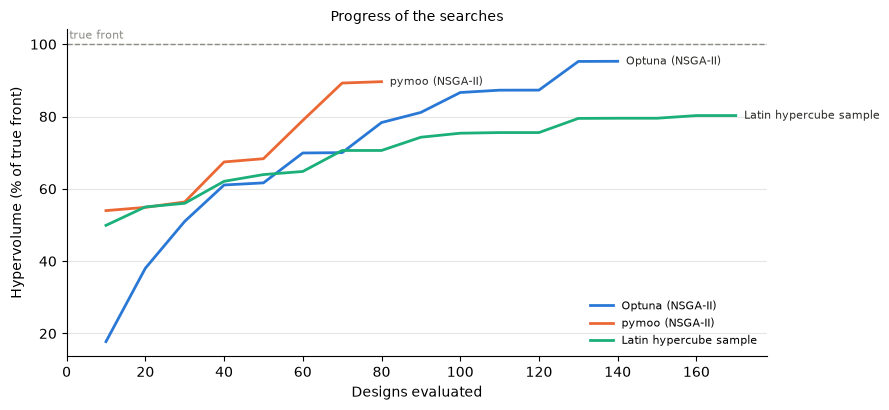

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for (name, series), color in zip(progress.items(), (BLUE, ORANGE, AQUA)):
    ax.plot(series.index, series.values, color=color, lw=2, label=name)
    ax.annotate(name, (series.index[-1], series.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK)
ax.axhline(100, color=GRAY, lw=1, ls="--")
ax.annotate("true front", (0, 100), xytext=(2, 4), textcoords="offset points", fontsize=8, color=GRAY)
ax.set(xlabel="Designs evaluated", ylabel="Hypervolume (% of true front)", xlim=(0, None))
ax.grid(axis="y", color="#e6e6e3", lw=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(loc="lower right", fontsize=8, frameon=False)
ax.set_title("Progress of the searches", fontsize=10)
fig.tight_layout()
plt.show()

Both optimizers find more of the hypervolume than a Latin hypercube sample of as many designs. Optuna (NSGA-II, searching the hierarchical space directly) finds 95% of the hypervolume of the true front with 140 designs, 13% of the space. pymoo (NSGA-II, searching the encoded space) finds 90% with 87 designs: its 200 proposals include many that encode the same design or that violate the constraints, which are not evaluated. The sample finds 80% with 176 designs. The searches stop at their budget of proposals, not at convergence: a larger budget, or screening, would bring them closer to the true front. Their results also depend on their seeds, so compare several seeds before relying on one.

## Summary

* A `DesignSpace` declares a hierarchical trade space, with choices between alternatives (`Choice`), repeated elements such as orbit planes (`Repeat`), bounds that depend on other variables, constraints that measure their violation, and uncertain parameters (`Uncertain`) drawn for each replicate. Building blocks declare common constellation layouts (`walker_space` and `sso_planes_space`) and build their satellites with instruments or entries of the instrument catalog (`build_constellation`).
* A `Study` evaluates designs in replicates, in parallel, with a `SatelliteCache` that analyzes each distinct satellite once and a `ResultStore` that keeps its evaluations (by the fingerprint of the study, so that a changed study evaluates its designs again). Every design of a space of about a thousand designs can be evaluated in minutes.
* Statistical sufficiency is measured by the sampling error of the statistic that observations estimate (`tatc.analysis.estimate_sampling_error`), which counts of samples overstate when samples cluster in time, as they do in a single plane; revisit statistics and local time coverage explain it.
* The front of the means of the replicates is uncertain: `pareto_probability` finds the designs whose efficiency the replicates settle, and those that are equally good candidates, and `refine` adds replicates only to the latter, with a tolerance of differences that do not matter. `confirm` evaluates the selected designs with new replicates, which removes the optimism of selecting the best of many nearly equal designs.
* Statistics other than means (such as a `Quantile` or the `Probability` of meeting a threshold) state how reliably a design performs, and `Requirement`s on them are output constraints. Simulated missions (`Deployment.simulate`) draw the failures of satellites and launches from lives whose failure rates vary over the lifecycle (`FailureModel`), and restore them or not (`RestorationPolicy`, by spares in orbit or on the ground, or by producing new ones), for both the cost and the capability of each policy; the policy is a decision of each design (`policy_space`, configured by `configure`), on the front with the design. `sensitivity` finds the design variables that drive each objective.
* `screen` evaluates every design with a cheap study and the best with the full one, which finds the front at a fraction of the cost if the cheap study ranks designs as the full one does.
* A `DeploymentSchedule` plans each design's deployment from rates of production and launch, which dates its costs and divides its mission into phases of the satellites that fly, evaluated with the observations of the full constellation for the mean capability over the mission and the time until a requirement is met.
* A `CostModel` estimates the life-cycle cost of each deployment from the costs of its satellites, launches, and operations (given by the study), with uncertain growth whose quantiles give the cost at a confidence level, as an objective or a requirement in place of the numbers of satellites and planes.
* `optimize_optuna` and `optimize_pymoo` search spaces too large to enumerate, and find most of the front with a fraction of the designs.

The sampling error here is that of a model of the field (an exponential correlation in time with a decorrelation time of 3 hours); with a simulation of the field (a nature run), `tatc.analysis.sample_field` and `compare_sampled_means` measure it directly. The costs are illustrative, and the numbers of satellites and planes, proxies of cost in the other sections. The uncertainties are those of the sample of points and the failures of satellites; others (such as the phase of the satellites or the period of the analysis) are further `Uncertain` parameters of the design space.